In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display plots inline
%matplotlib inline

# Set aesthetic defaults for charts
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

In [2]:
import os
import pandas as pd

DATA_URL = "https://data.open-power-system-data.org/time_series/2020-10-06/time_series_60min_singleindex.csv"
OUTPUT_FILE = "german_grid_load.csv"

# 1. Fetch raw data directly
print("Fetching hourly energy data from Open Power System Data (this may take a minute)...")
target_column = "DE_load_actual_entsoe_transparency"
columns_to_load = ["utc_timestamp", target_column]
df_raw = pd.read_csv(DATA_URL, usecols=columns_to_load, parse_dates=["utc_timestamp"])

# 2. Clean and rename
df = df_raw.rename(columns={"utc_timestamp": "timestamp", target_column: "load_mw"})
df = df.dropna(subset=["load_mw"]).copy()
df = df.set_index("timestamp").sort_index()

# 3. Slice the last 4,320 hours (180 days)
df = df.tail(4320).copy()

# 4. Save clean local copy
df.to_csv(OUTPUT_FILE)
print("Download and preprocessing complete!")
print(f"Total rows in df: {len(df)}")
df.head()

Fetching hourly energy data from Open Power System Data (this may take a minute)...
Download and preprocessing complete!
Total rows in df: 4320


,load_mw
timestamp,
2020-04-04 00:00:00+00:00,42387.0
2020-04-04 01:00:00+00:00,42234.0
2020-04-04 02:00:00+00:00,42719.0
2020-04-04 03:00:00+00:00,43109.0
2020-04-04 04:00:00+00:00,43318.0


In [3]:
# 7 days * 24 hours = 168 hours for testing
test_periods = 168

train_df = df.iloc[:-test_periods].copy()
test_df = df.iloc[-test_periods:].copy()

print(f"Total records: {len(df)}")
print(f"Training records: {len(train_df)} (Historical base)")
print(f"Testing records: {len(test_df)} (Next 7 days out-of-sample)")

Total records: 4320
Training records: 4152 (Historical base)
Testing records: 168 (Next 7 days out-of-sample)


In [4]:
#Creating baselines for the model
def moving_average_forecast(series, n_window, horizon):
    """Calculates a moving average forecast.
    series: historical pandas Series (training load data)
    n_window: number of periods to consider in average (e.g., 24 hours)
    horizon: number of periods into the future to forecast (e.g., 168 hours)
    """
    # Convert series to a standard Python list or numpy array for simple indexing
    history = list(series.values)
    forecasts = []

    # 1. First out-of-sample forecast is the average of the last n periods
    first_forecast = np.mean(history[-n_window:])

    # 2. As specified in slide 41 / Exercise 7b, carry forward unchanged for the horizon
    forecasts = [first_forecast] * horizon

    return forecasts

# Let's run a 24-hour Moving Average over our 168-hour test window
ma_24_predictions = moving_average_forecast(train_df["load_mw"], n_window=24, horizon=test_periods)

# Add predictions to our test DataFrame for easy comparison
test_df["forecast_ma24"] = ma_24_predictions
test_df[["load_mw", "forecast_ma24"]].head()

,load_mw,forecast_ma24
timestamp,,
2020-09-24 00:00:00+00:00,43985.0,56557.833333
2020-09-24 01:00:00+00:00,43704.0,56557.833333
2020-09-24 02:00:00+00:00,44766.0,56557.833333
2020-09-24 03:00:00+00:00,48727.0,56557.833333
2020-09-24 04:00:00+00:00,56448.0,56557.833333


In [5]:
def compute_metrics(actual, forecast):
    """Calculates Bias, MAE, RMSE, and MAPE between actual and forecast arrays."""
    actual = np.array(actual)
    forecast = np.array(forecast)

    # Error vector e_t = f_t - d_t
    errors = forecast - actual

    bias = np.mean(errors)
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))
    mape = np.mean(np.abs(errors / actual)) * 100

    return {
        "Bias (MW)": round(bias, 2),
        "MAE (MW)": round(mae, 2),
        "RMSE (MW)": round(rmse, 2),
        "MAPE (%)": round(mape, 2)
    }

# Quick test on our 24h Moving Average
ma_overall_metrics = compute_metrics(test_df["load_mw"], test_df["forecast_ma24"])
print("24h Moving Average Overall Test Performance:")
for k, v in ma_overall_metrics.items():
    print(f"  {k}: {v}")

24h Moving Average Overall Test Performance:
  Bias (MW): 2390.58
  MAE (MW): 8119.41
  RMSE (MW): 9288.33
  MAPE (%): 16.43


In [6]:
# 1. Build a simple Python lookup dictionary: {(dayofweek, hour): mean_load}
profile_dict = (
    train_df.groupby([train_df.index.dayofweek, train_df.index.hour])["load_mw"]
    .mean()
    .to_dict()
)

# 2. Map directly using the test set index timestamps
test_df["forecast_profile"] = [
    profile_dict.get((ts.dayofweek, ts.hour), train_df["load_mw"].mean())
    for ts in test_df.index
]

# 3. Check the first 5 rows
test_df[["load_mw", "forecast_ma24", "forecast_profile"]].head()

,load_mw,forecast_ma24,forecast_profile
timestamp,,,
2020-09-24 00:00:00+00:00,43985.0,56557.833333,41143.208333
2020-09-24 01:00:00+00:00,43704.0,56557.833333,41145.166667
2020-09-24 02:00:00+00:00,44766.0,56557.833333,42078.333333
2020-09-24 03:00:00+00:00,48727.0,56557.833333,44668.083333
2020-09-24 04:00:00+00:00,56448.0,56557.833333,50434.791667


In [7]:
import numpy as np

def calculate_metrics(y_true, y_pred):
    bias = np.mean(y_pred - y_true)
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"Bias (MW)": bias, "MAE (MW)": mae, "RMSE (MW)": rmse, "MAPE (%)": mape}

# Compute metrics for both models
metrics_ma24 = calculate_metrics(test_df["load_mw"], test_df["forecast_ma24"])
metrics_profile = calculate_metrics(test_df["load_mw"], test_df["forecast_profile"])

# Display comparison in a clean DataFrame
import pandas as pd
comparison_df = pd.DataFrame([metrics_ma24, metrics_profile], index=["Moving Average (24h)", "Seasonal Profile"])
print(comparison_df.round(2))

                      Bias (MW)  MAE (MW)  RMSE (MW)  MAPE (%)
Moving Average (24h)    2390.58   8119.41    9288.33     16.43
Seasonal Profile       -4009.87   4009.87    4188.57      7.38


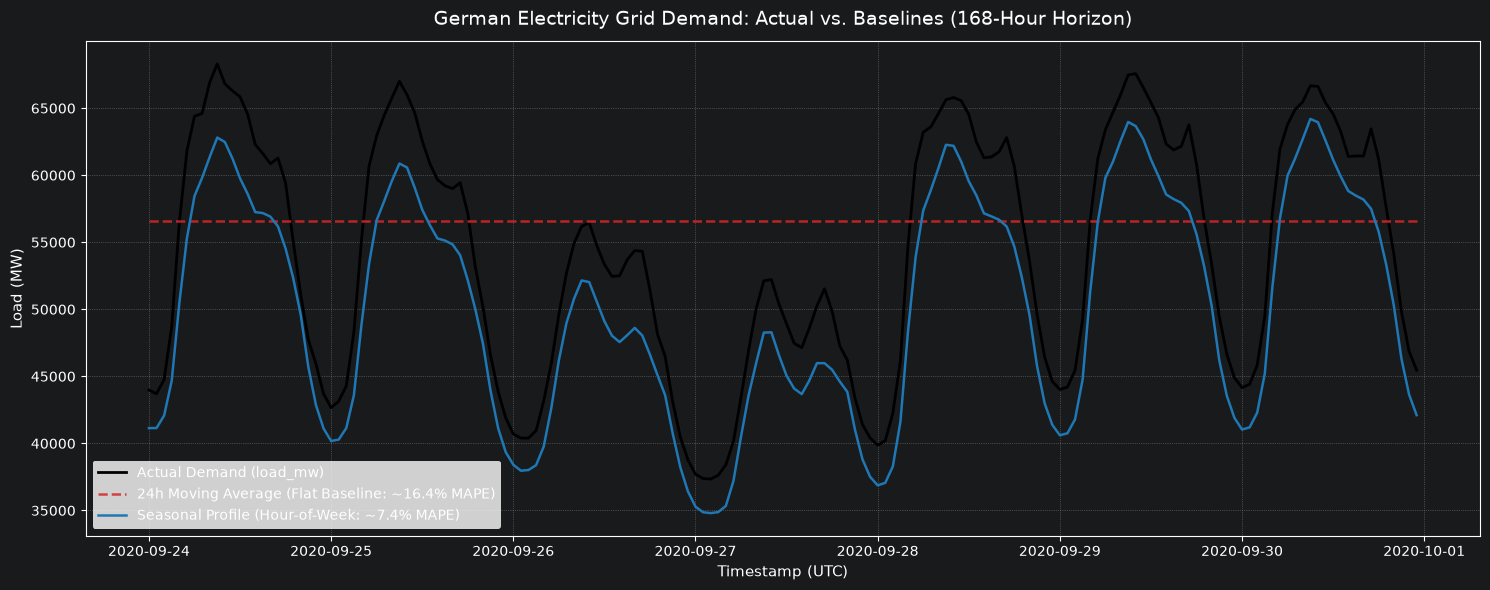

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

# 1. Ground truth
plt.plot(test_df.index, test_df["load_mw"], label="Actual Demand (load_mw)", color="black", linewidth=2.0)

# 2. Moving average baseline (the flat line error)
plt.plot(test_df.index, test_df["forecast_ma24"], label="24h Moving Average (Flat Baseline: ~16.4% MAPE)",
         color="#d62728", linestyle="--", linewidth=1.8, alpha=0.85)

# 3. Seasonal profile
plt.plot(test_df.index, test_df["forecast_profile"], label="Seasonal Profile (Hour-of-Week: ~7.4% MAPE)",
         color="#1f77b4", linewidth=1.8)

plt.title("German Electricity Grid Demand: Actual vs. Baselines (168-Hour Horizon)", fontsize=14, pad=12)
plt.xlabel("Timestamp (UTC)", fontsize=11)
plt.ylabel("Load (MW)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=10)
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import pandas as pd

# Work on a copy of the cleaned 4,320-hour dataset
df_feat = df.copy()

# 1. Calendar & Cyclical Features
df_feat["hour"] = df_feat.index.hour
df_feat["dayofweek"] = df_feat.index.dayofweek
df_feat["is_weekend"] = df_feat["dayofweek"].isin([5, 6]).astype(int)

# 24-hour cyclical encoding
df_feat["sin_hour"] = np.sin(2 * np.pi * df_feat["hour"] / 24)
df_feat["cos_hour"] = np.cos(2 * np.pi * df_feat["hour"] / 24)

# 7-day cyclical encoding
df_feat["sin_dow"] = np.sin(2 * np.pi * df_feat["dayofweek"] / 7)
df_feat["cos_dow"] = np.cos(2 * np.pi * df_feat["dayofweek"] / 7)

# 2. Week-Ahead Lag Features (strictly >= 168 hours to prevent future leakage)
df_feat["lag_168"] = df_feat["load_mw"].shift(168)      # Exact same hour 1 week ago
df_feat["lag_169"] = df_feat["load_mw"].shift(169)
df_feat["lag_192"] = df_feat["load_mw"].shift(192)      # 8 days ago
df_feat["lag_336"] = df_feat["load_mw"].shift(336)      # Exactly 2 weeks ago

# 3. Rolling Statistics over Historical Lags
# Shift by 168 first so rolling calculations never look into the test week
df_feat["rolling_mean_168"] = df_feat["load_mw"].shift(168).rolling(window=168).mean()
df_feat["rolling_std_168"] = df_feat["load_mw"].shift(168).rolling(window=168).std()

# Drop rows with NaN values generated by lag/rolling shifts
df_feat = df_feat.dropna().copy()

print(f"Dataset shape after feature creation: {df_feat.shape}")
df_feat.head(3)

Dataset shape after feature creation: (3984, 14)


,load_mw,hour,dayofweek,is_weekend,sin_hour,cos_hour,sin_dow,cos_dow,lag_168,lag_169,lag_192,lag_336,rolling_mean_168,rolling_std_168
timestamp,,,,,,,,,,,,,,
2020-04-18 00:00:00+00:00,38039.0,0,5,1,0.000000,1.000000,-0.974928,-0.222521,36020.0,37226.0,37165.0,42387.0,48459.255952,6929.591752
2020-04-18 01:00:00+00:00,38026.0,1,5,1,0.258819,0.965926,-0.974928,-0.222521,35816.0,36020.0,36760.0,42234.0,48421.053571,6981.612427
2020-04-18 02:00:00+00:00,39182.0,2,5,1,0.500000,0.866025,-0.974928,-0.222521,36151.0,35816.0,36995.0,42719.0,48381.958333,7031.941810


In [10]:
# Select feature columns and target
features = [
    "sin_hour", "cos_hour", "sin_dow", "cos_dow", "is_weekend",
    "lag_168", "lag_169", "lag_192", "lag_336",
    "rolling_mean_168", "rolling_std_168"
]
target = "load_mw"

test_horizon = 168

# Strict chronological split
X_train = df_feat.iloc[:-test_horizon][features]
y_train = df_feat.iloc[:-test_horizon][target]

X_test = df_feat.iloc[-test_horizon:][features]
y_test = df_feat.iloc[-test_horizon:][target]

print(f"X_train shape: {X_train.shape} (~{len(X_train)//24} days)")
print(f"X_test shape:  {X_test.shape} (exactly {len(X_test)//24} days)")

X_train shape: (3816, 11) (~159 days)
X_test shape:  (168, 11) (exactly 7 days)


In [11]:
import lightgbm as lgb

# 1. Point Model (Median / Quantile 0.50)
model_p50 = lgb.LGBMRegressor(
    objective="quantile",
    alpha=0.50,
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42
)
model_p50.fit(X_train, y_train)
test_df.loc[X_test.index, "forecast_lgb_p50"] = model_p50.predict(X_test)

# 2. Lower Bound (Quantile 0.10)
model_p10 = lgb.LGBMRegressor(
    objective="quantile",
    alpha=0.10,
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42
)
model_p10.fit(X_train, y_train)
test_df.loc[X_test.index, "forecast_lgb_p10"] = model_p10.predict(X_test)

# 3. Upper Bound (Quantile 0.90)
model_p90 = lgb.LGBMRegressor(
    objective="quantile",
    alpha=0.90,
    n_estimators=300,
    learning_rate=0.03,
    num_leaves=31,
    random_state=42
)
model_p90.fit(X_train, y_train)
test_df.loc[X_test.index, "forecast_lgb_p90"] = model_p90.predict(X_test)

print("LightGBM models trained successfully!")
test_df[["load_mw", "forecast_profile", "forecast_lgb_p50", "forecast_lgb_p10", "forecast_lgb_p90"]].head()

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000307 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1585
[LightGBM] [Info] Number of data points in the train set: 3816, number of used features: 11
[LightGBM] [Info] Start training from score 49566.500000
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000149 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1585
[LightGBM] [Info] Number of data points in the train set: 3816, number of used features: 11
[LightGBM] [Info] Start training from score 38808.000000
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000168 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1585
[LightGBM] [Info] Number of data points in the train set: 3816, number of used features: 11
[LightGBM] [Info] Star

,load_mw,forecast_profile,forecast_lgb_p50,forecast_lgb_p10,forecast_lgb_p90
timestamp,,,,,
2020-09-24 00:00:00+00:00,43985.0,41143.208333,42777.360766,41779.754339,43754.907933
2020-09-24 01:00:00+00:00,43704.0,41145.166667,42898.380446,41922.242546,43760.795331
2020-09-24 02:00:00+00:00,44766.0,42078.333333,44020.607272,43344.708061,44693.387460
2020-09-24 03:00:00+00:00,48727.0,44668.083333,47123.793518,46211.957145,48359.635221
2020-09-24 04:00:00+00:00,56448.0,50434.791667,55953.510842,53630.631530,56446.457267


In [12]:
# Calculate metrics for LightGBM P50
valid_mask = test_df["forecast_lgb_p50"].notna()
metrics_lgb = calculate_metrics(test_df.loc[valid_mask, "load_mw"], test_df.loc[valid_mask, "forecast_lgb_p50"])

# Build the complete comparison table
comparison_df = pd.DataFrame(
    [metrics_ma24, metrics_profile, metrics_lgb],
    index=["Moving Average (24h)", "Seasonal Profile", "LightGBM (P50)"]
)
print(comparison_df.round(2))

                      Bias (MW)  MAE (MW)  RMSE (MW)  MAPE (%)
Moving Average (24h)    2390.58   8119.41    9288.33     16.43
Seasonal Profile       -4009.87   4009.87    4188.57      7.38
LightGBM (P50)         -2125.98   2125.98    2296.20      3.95


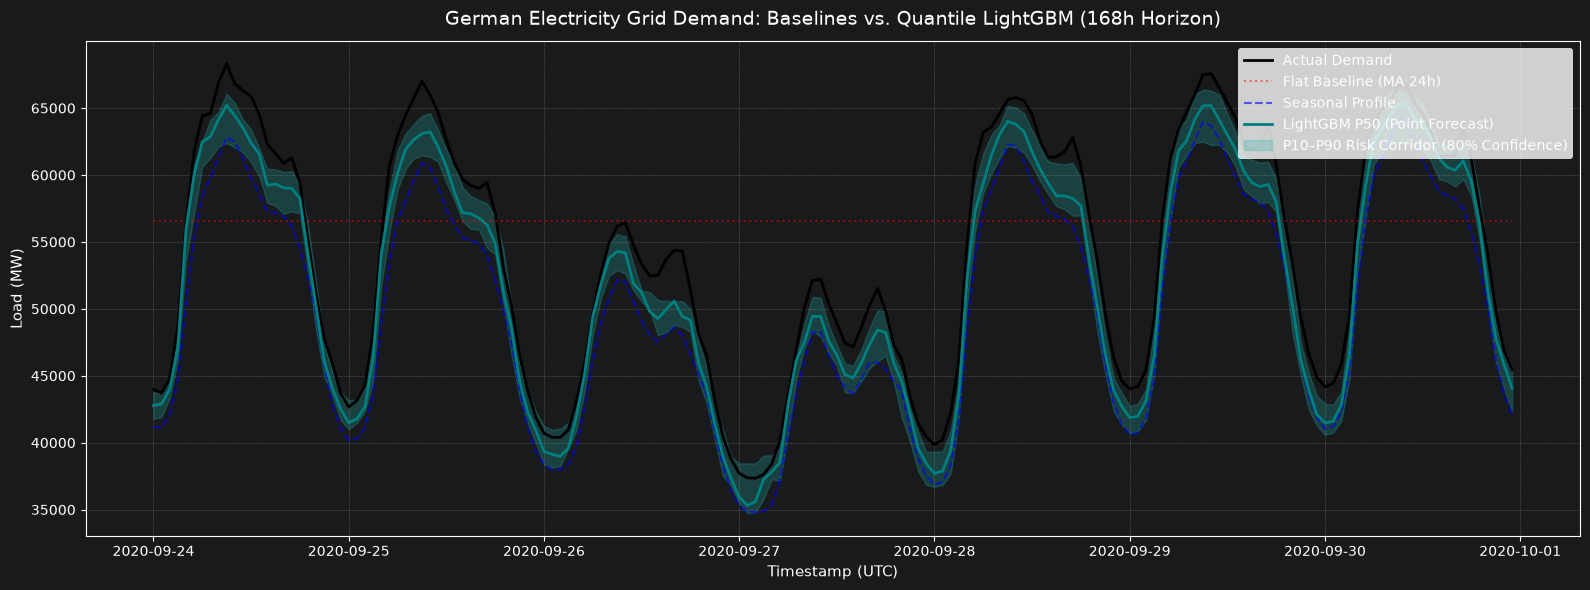

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

# 1. Ground truth
plt.plot(test_df.index, test_df["load_mw"], label="Actual Demand", color="black", linewidth=2.0)

# 2. Baselines
plt.plot(test_df.index, test_df["forecast_ma24"], label="Flat Baseline (MA 24h)", color="red", linestyle=":", alpha=0.5)
plt.plot(test_df.index, test_df["forecast_profile"], label="Seasonal Profile", color="blue", linestyle="--", alpha=0.6)

# 3. LightGBM P50 Point Forecast
plt.plot(test_df.index, test_df["forecast_lgb_p50"], label="LightGBM P50 (Point Forecast)", color="#008080", linewidth=2.0)

# 4. LightGBM P10-P90 Risk Corridor (Shaded Confidence Band)
plt.fill_between(
    test_df.index,
    test_df["forecast_lgb_p10"],
    test_df["forecast_lgb_p90"],
    color="#20b2aa",
    alpha=0.25,
    label="P10–P90 Risk Corridor (80% Confidence)"
)

plt.title("German Electricity Grid Demand: Baselines vs. Quantile LightGBM (168h Horizon)", fontsize=14, pad=12)
plt.xlabel("Timestamp (UTC)", fontsize=11)
plt.ylabel("Load (MW)", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", fontsize=10)
plt.tight_layout()
plt.show()

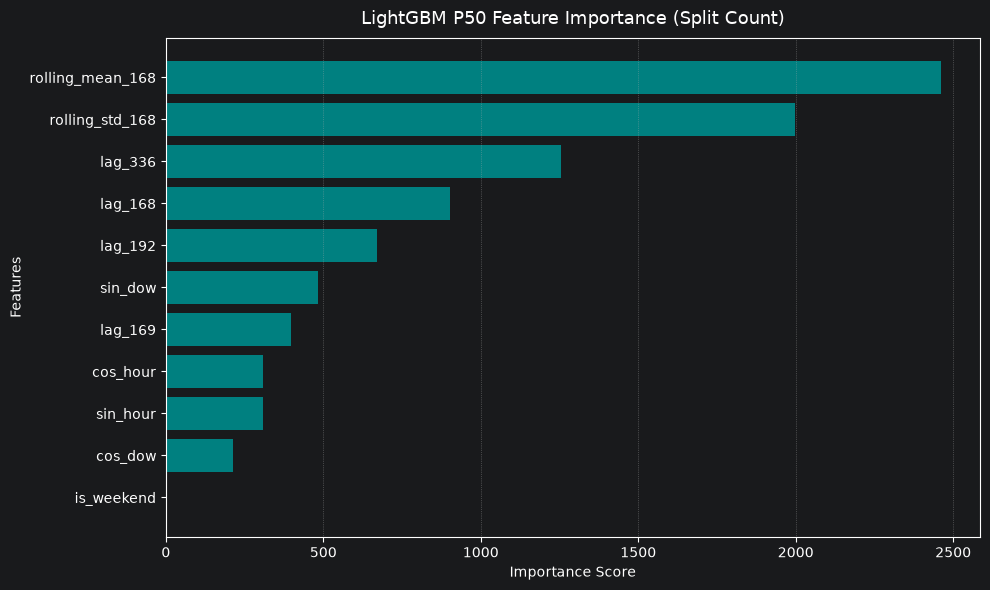

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances from the primary point model (P50)
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model_p50.feature_importances_
}).sort_values(by="Importance", ascending=True)

# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="#008080")
plt.title("LightGBM P50 Feature Importance (Split Count)", fontsize=13, pad=10)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [15]:
# Calculate empirical coverage of the P10-P90 corridor
inside_corridor = (
    (test_df["load_mw"] >= test_df["forecast_lgb_p10"]) &
    (test_df["load_mw"] <= test_df["forecast_lgb_p90"])
)

coverage_rate = inside_corridor.mean() * 100
total_hours = len(inside_corridor)
covered_hours = inside_corridor.sum()

print(f"Empirical Coverage: {coverage_rate:.2f}% (Expected ~80%)")
print(f"Hours within corridor: {covered_hours} out of {total_hours} hours")

Empirical Coverage: 24.40% (Expected ~80%)
Hours within corridor: 41 out of 168 hours


In [16]:
# Print consolidated summary
print("=== FINAL MODEL BENCHMARK RESULTS ===")
print(comparison_df.round(2).to_string())

=== FINAL MODEL BENCHMARK RESULTS ===
                      Bias (MW)  MAE (MW)  RMSE (MW)  MAPE (%)
Moving Average (24h)    2390.58   8119.41    9288.33     16.43
Seasonal Profile       -4009.87   4009.87    4188.57      7.38
LightGBM (P50)         -2125.98   2125.98    2296.20      3.95
